# Task 2 — Notebook 1: Read and Join the Tables

This notebook creates the first clean order-level dataset for the machine-learning pipeline.

The main rule is simple: **one row must represent one order**. Tables with many rows per order, such as items, payments, and reviews, are aggregated before they are joined to the orders table.

**Input:** PostgreSQL tables created in Task 1.

**Output:** `artifacts/tables/01_joined_ml_table.parquet`

This notebook does not create the `is_late` target. Target creation belongs to Notebook 2.


## 1. Imports and project paths

The code below uses environment variables for database credentials. It does not store the password in the notebook.


In [1]:
from pathlib import Path
import os
import getpass
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text, inspect

sns.set_theme(style="whitegrid", context="notebook")

import sys

src_dir = Path.cwd().resolve()
while src_dir != src_dir.parent and not (src_dir / "Task2").is_dir():
    src_dir = src_dir.parent
src_dir = src_dir / "Task2" / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from config import find_project_root

PROJECT_ROOT = find_project_root()
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
TABLES_DIR = ARTIFACTS_DIR / "tables"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
CHARTS_DIR = ARTIFACTS_DIR / "charts"

for folder in [TABLES_DIR, REPORTS_DIR, CHARTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DB_HOST = os.getenv("OLIST_DB_HOST", "localhost")
DB_PORT = os.getenv("OLIST_DB_PORT", "5432")
DB_NAME = os.getenv("OLIST_DB_NAME", "olist")
DB_USER = os.getenv("OLIST_DB_USER", "postgres")
DB_PASSWORD = os.getenv("OLIST_DB_PASSWORD") or getpass.getpass("PostgreSQL password: ")

connection_url = f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(connection_url, pool_pre_ping=True)

with engine.connect() as connection:
    print(connection.execute(text("SELECT version();")).scalar_one())

print(f"Tables artifact folder: {TABLES_DIR}")


PostgreSQL 17.10 on x86_64-windows, compiled by msvc-19.44.35226, 64-bit
Tables artifact folder: C:\Users\HP\Desktop\MLOps\Task2\artifacts\tables


## 2. Read the source tables

We read each table separately before joining. This makes it easier to understand the size and role of every table.


In [2]:
expected_tables = [
    "olist_customers",
    "olist_geolocation",
    "olist_orders",
    "olist_order_items",
    "olist_order_payments",
    "olist_order_reviews",
    "olist_products",
    "olist_sellers",
    "product_category_name_translation",
]

available_tables = set(inspect(engine).get_table_names())
missing_tables = sorted(set(expected_tables) - available_tables)
assert not missing_tables, f"Missing tables: {missing_tables}"

tables = {}
summary_rows = []

for table_name in expected_tables:
    table = pd.read_sql_table(table_name, engine)
    tables[table_name] = table
    summary_rows.append({
        "table": table_name,
        "rows": len(table),
        "columns": len(table.columns),
        "missing_cells": int(table.isna().sum().sum()),
    })

table_summary = pd.DataFrame(summary_rows).sort_values("table").reset_index(drop=True)
display(table_summary)


,table,rows,columns,missing_cells
0,olist_customers,99441,5,0
1,olist_geolocation,1000163,5,0
2,olist_order_items,112650,7,0
3,olist_order_payments,103886,5,0
4,olist_order_reviews,99224,7,145903
5,olist_orders,99441,8,4908
6,olist_products,32951,9,2448
7,olist_sellers,3095,4,0
8,product_category_name_translation,71,2,0


## 3. Check the important keys

The checks below verify that the tables used as one-to-one parents have unique identifiers. Items and payments use composite keys because an order can contain multiple records.


In [3]:
key_checks = []

key_definitions = {
    "olist_customers": ["customer_id"],
    "olist_orders": ["order_id"],
    "olist_products": ["product_id"],
    "olist_sellers": ["seller_id"],
    "olist_order_items": ["order_id", "order_item_id"],
    "olist_order_payments": ["order_id", "payment_sequential"],
}

for table_name, key_columns in key_definitions.items():
    table = tables[table_name]
    unique_keys = table[key_columns].drop_duplicates().shape[0]
    null_keys = int(table[key_columns].isna().any(axis=1).sum())
    key_checks.append({
        "table": table_name,
        "key": ", ".join(key_columns),
        "rows": len(table),
        "unique_keys": unique_keys,
        "null_key_rows": null_keys,
        "duplicate_key_rows": len(table) - unique_keys,
    })

key_summary = pd.DataFrame(key_checks)
display(key_summary)

assert (key_summary["null_key_rows"] == 0).all(), "A required key contains null values."
assert (key_summary["duplicate_key_rows"] == 0).all(), "A required key is duplicated."


,table,key,rows,unique_keys,null_key_rows,duplicate_key_rows
0,olist_customers,customer_id,99441,99441,0,0
1,olist_orders,order_id,99441,99441,0,0
2,olist_products,product_id,32951,32951,0,0
3,olist_sellers,seller_id,3095,3095,0,0
4,olist_order_items,"order_id, order_item_id",112650,112650,0,0
5,olist_order_payments,"order_id, payment_sequential",103886,103886,0,0


## 4. Create order-level summaries

The source tables have different grains. We aggregate each many-row table by `order_id` before joining it to the orders table. This prevents duplicated sums and fan-out joins.


In [4]:
orders = tables["olist_orders"].copy()
customers = tables["olist_customers"].copy()
items = tables["olist_order_items"].copy()
payments = tables["olist_order_payments"].copy()
reviews = tables["olist_order_reviews"].copy()
products = tables["olist_products"].copy()
sellers = tables["olist_sellers"].copy()

# Add product and seller information to each item before summarising by order.
items_with_products = items.merge(
    products[["product_id", "product_category_name", "product_weight_g", "product_photos_qty"]],
    on="product_id",
    how="left",
    validate="many_to_one",
)

items_with_details = items_with_products.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left",
    validate="many_to_one",
)

items_by_order = (
    items_with_details.groupby("order_id", as_index=False)
    .agg(
        num_items=("order_item_id", "count"),
        num_distinct_products=("product_id", "nunique"),
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        num_sellers=("seller_id", "nunique"),
        num_product_categories=("product_category_name", "nunique"),
        avg_product_weight_g=("product_weight_g", "mean"),
        avg_product_photos_qty=("product_photos_qty", "mean"),
        seller_state_count=("seller_state", "nunique"),
    )
)

payments_by_order = (
    payments.groupby("order_id", as_index=False)
    .agg(
        payment_record_count=("payment_sequential", "count"),
        total_payment_value=("payment_value", "sum"),
        max_payment_installments=("payment_installments", "max"),
    )
)

reviews_by_order = (
    reviews.groupby("order_id", as_index=False)
    .agg(
        review_record_count=("review_id", "nunique"),
        avg_review_score=("review_score", "mean"),
    )
)

print("Items summary:", items_by_order.shape)
print("Payments summary:", payments_by_order.shape)
print("Reviews summary:", reviews_by_order.shape)


Items summary: (98666, 10)
Payments summary: (99440, 4)
Reviews summary: (98673, 3)


## 5. Join everything at order level

The orders table is the base table. Every other input is now either one-to-one or already aggregated by `order_id`.


In [5]:
customer_columns = [
    "customer_id",
    "customer_unique_id",
    "customer_zip_code_prefix",
    "customer_city",
    "customer_state",
]

joined = orders.merge(
    customers[customer_columns],
    on="customer_id",
    how="left",
    validate="one_to_one",
).merge(
    items_by_order,
    on="order_id",
    how="left",
    validate="one_to_one",
).merge(
    payments_by_order,
    on="order_id",
    how="left",
    validate="one_to_one",
).merge(
    reviews_by_order,
    on="order_id",
    how="left",
    validate="one_to_one",
)

print(f"Joined shape: {joined.shape}")
print(f"Unique order IDs: {joined['order_id'].nunique():,}")

assert joined["order_id"].is_unique, "The final table must have one row per order_id."
assert len(joined) == len(orders), "The join changed the number of orders."
display(joined.head())


Joined shape: (99441, 26)
Unique order IDs: 99,441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,num_sellers,num_product_categories,avg_product_weight_g,avg_product_photos_qty,seller_state_count,payment_record_count,total_payment_value,max_payment_installments,review_record_count,avg_review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1.0,1.0,500.0,4.0,1.0,3.0,38.71,1.0,1.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1.0,1.0,400.0,1.0,1.0,1.0,141.46,1.0,1.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,1.0,420.0,1.0,1.0,1.0,179.12,3.0,1.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,...,1.0,1.0,450.0,3.0,1.0,1.0,72.20,1.0,1.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,...,1.0,1.0,250.0,4.0,1.0,1.0,28.62,1.0,1.0,5.0


## 6. Lightweight data-quality EDA

Detailed EDA belongs to Notebook 4. Here we use two simple visuals to confirm that the source data and joined table look reasonable.


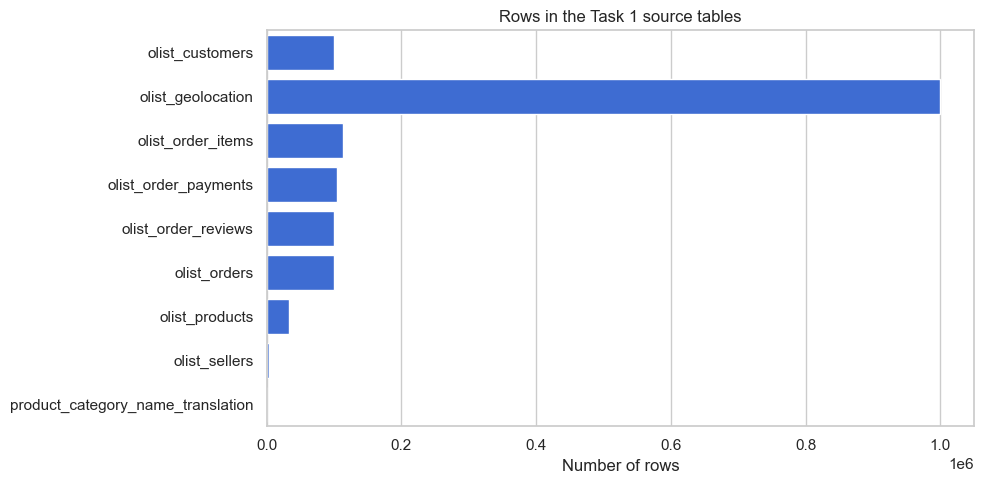

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=table_summary, x="rows", y="table", color="#2563eb", ax=ax)
ax.set_title("Rows in the Task 1 source tables")
ax.set_xlabel("Number of rows")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
fig.savefig(CHARTS_DIR / "01_source_table_sizes.png", dpi=150, bbox_inches="tight")


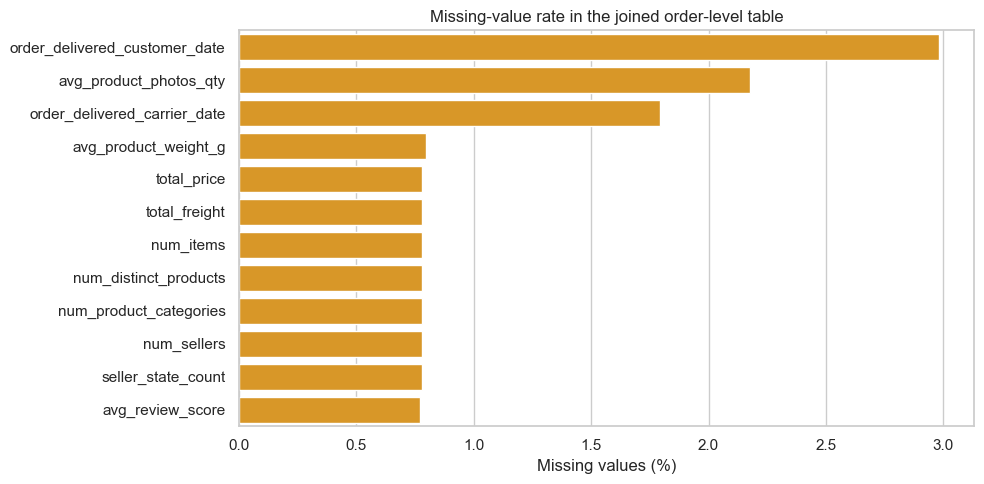

In [7]:
missing = joined.isna().mean().sort_values(ascending=False).head(12)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(10, 5))
if len(missing) > 0:
    sns.barplot(x=missing.values * 100, y=missing.index, color="#f59e0b", ax=ax)
    ax.set_title("Missing-value rate in the joined order-level table")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("")
else:
    ax.text(0.5, 0.5, "No missing values", ha="center", va="center")
    ax.set_axis_off()
plt.tight_layout()
plt.show()
fig.savefig(CHARTS_DIR / "01_joined_missingness.png", dpi=150, bbox_inches="tight")


## 7. Save the first artifact

The Parquet file is the input for Notebook 2. Metadata records the table grain and the aggregation rules used to create it.


In [8]:
output_path = TABLES_DIR / "01_joined_ml_table.parquet"
metadata_path = REPORTS_DIR / "01_joined_ml_table_metadata.json"

joined.to_parquet(output_path, index=False)

metadata = {
    "artifact": str(output_path),
    "grain": "one row per order_id",
    "rows": int(len(joined)),
    "columns": int(len(joined.columns)),
    "source_tables": expected_tables,
    "aggregated_tables": {
        "olist_order_items": "aggregated by order_id before joining",
        "olist_order_payments": "aggregated by order_id before joining",
        "olist_order_reviews": "aggregated by order_id before joining",
    },
    "quality_checks": {
        "unique_order_id": bool(joined["order_id"].is_unique),
        "same_order_count_as_orders": bool(len(joined) == len(orders)),
    },
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved: {output_path}")
print(f"Saved: {metadata_path}")


Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\tables\01_joined_ml_table.parquet
Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\reports\01_joined_ml_table_metadata.json


## 8. Final checks

Notebook 1 is complete when the final table has one row per order, the artifact exists, and the two basic quality conditions pass.


In [9]:
assert output_path.exists(), "The joined-table artifact was not created."
assert joined["order_id"].is_unique
assert len(joined) == len(orders)
print("ALL NOTEBOOK 1 CHECKS PASSED")


ALL NOTEBOOK 1 CHECKS PASSED
